In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.preprocessing import StandardScaler


TASK 1

Student who studies 5.5 hrs: [73.56]
Student who studies 8 hrs: [98.65]

Slope: [10.04]
Intercept: 18.36

MAE:  1.3143369175627242  
MSE:  2.0464157706093187                                
R2 :  0.9927701262299617


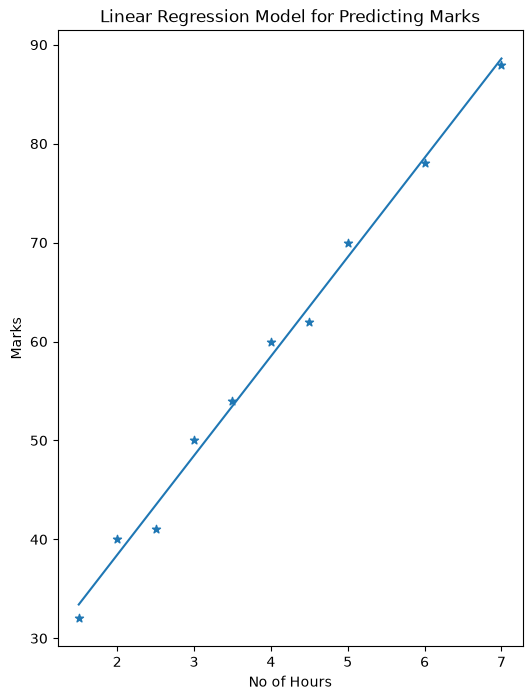

In [ ]:
hours = pd.DataFrame([[1.5], [2.0], [2.5], [3.0], [3.5],[4.0], [4.5], [5.0], [6.0], [7.0]])
marks = pd.Series([32, 40, 41, 50, 54, 60, 62, 70, 78, 88])

model= LinearRegression()
model.fit(hours,marks)

print(f"""Student who studies 5.5 hrs: {model.predict([[5.5]]).round(2)}
Student who studies 8 hrs: {model.predict([[8]]).round(2)}\n"""
)

fig,ax =plt.subplots(figsize=(6,8))
ax.scatter(hours,marks,marker='*')
ax.set_xlabel("No of Hours")
ax.set_ylabel("Marks")
ax.set_title("Linear Regression Model for Predicting Marks")
print("Slope:", model.coef_.round(2))
print("Intercept:", model.intercept_.round(2))
lineeq= model.coef_*hours + model.intercept_
ax.plot(hours,lineeq)

ypred = model.predict(hours)

print(f"""\nMAE:  {mean_absolute_error(marks,ypred )}  
MSE:  {mean_squared_error(marks,ypred)}                                
R2 :  {r2_score(marks,ypred)}""")




TASK 2


--------Learning Rate : 0.001--------

Epoch: 0, MSE: 3589.3000
Epoch: 100, MSE: 38.4762
Epoch: 200, MSE: 34.8470
Epoch: 300, MSE: 32.9607
Epoch: 400, MSE: 31.1835
W(gradient) : 12.94
B(intercept) : 5.05


------Learning Rate : 0.01-------

Epoch: 0, MSE: 3589.3000
Epoch: 100, MSE: 22.4555
Epoch: 200, MSE: 13.3275
Epoch: 300, MSE: 8.2820
Epoch: 400, MSE: 5.4931
W(gradient) : 10.8
B(intercept) : 14.85


------Learning Rate : 0.05-------

Epoch: 0, MSE: 3589.3000
Epoch: 100, MSE: 3.9181
Epoch: 200, MSE: 2.1413
Epoch: 300, MSE: 2.0512
Epoch: 400, MSE: 2.0467
W(gradient) : 10.04
B(intercept) : 18.35


(np.float64(10.037792562108125), np.float64(18.351287823522476))

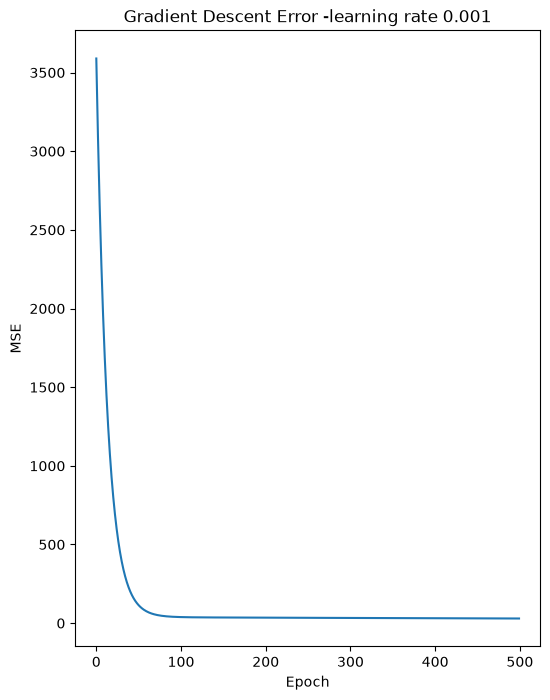

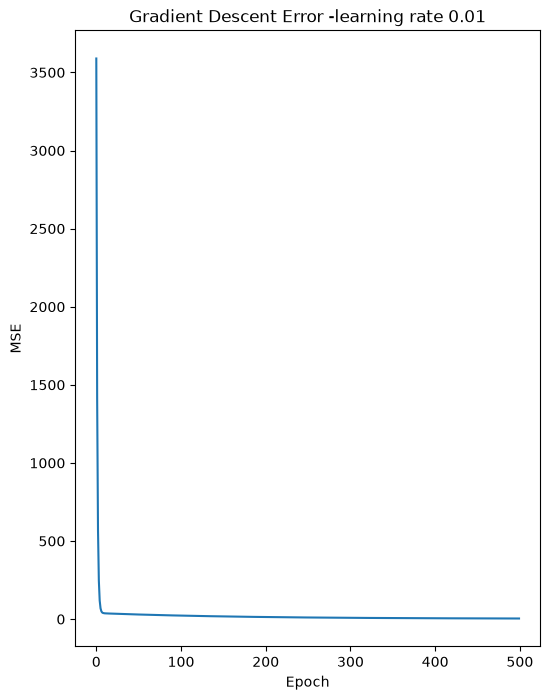

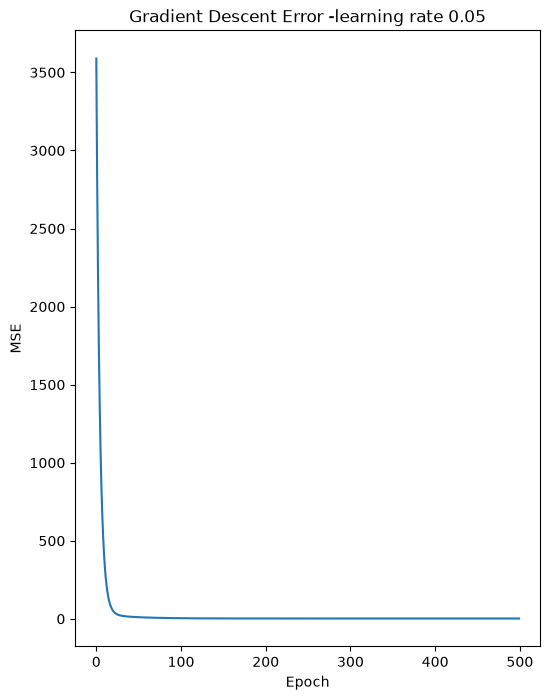

In [112]:
def grad_desc(x,y,lr,epochs):
    w,b=0,0
    
    mse_hist=[]
    for i in range(epochs):
        ypred = w * x + b
        error = ypred - y
        mse = np.mean(error ** 2)
        mse_hist.append(mse)

        dw = 2 * np.mean(error * x)
        db = 2 * np.mean(error)

        w -= lr * dw
        b -= lr * db

        if i % 100 == 0:
            print(f"Epoch: {i}, MSE: {mse:.4f}")
            
    fig,dx =plt.subplots(figsize=(6,8))
    dx.set_xlabel("Epoch")
    dx.set_ylabel("MSE")
    dx.set_title(f"Gradient Descent Error -learning rate {lr}")
    dx.plot(range(epochs), mse_hist)

    print(f"W(gradient) : {w.round(2)}")
    print(f"B(intercept) : {b.round(2)}")
    return w, b
    
    

hours = pd.DataFrame([[1.5], [2.0], [2.5], [3.0], [3.5],[4.0], [4.5], [5.0], [6.0], [7.0]])
marks = pd.Series([32, 40, 41, 50, 54, 60, 62, 70, 78, 88])

print("\n--------Learning Rate : 0.001--------\n")
grad_desc(hours[0],marks,0.001,500)
print("\n\n------Learning Rate : 0.01-------\n")
grad_desc(hours[0],marks,0.01,500)
print("\n\n------Learning Rate : 0.05-------\n")
grad_desc(hours[0],marks,0.05,500)



task 1 ,            m = 10.04  b = 18.36
task 2 , lr 0.001   m = 12.94  b = 5.05
task 2 , lr 0.01    m = 10.80  b = 14.85
task 2 , lr 0.05    m = 10.04  b = 18.35 

** so we can see they are pretty close , and also see the effect of learning rate 

TASK 3

In [108]:
df = pd.DataFrame({'experience': [1, 2, 3, None, 5, 6, 7, 8, 9, 10, 3, 5,],
                            'education':['BS', 'BS', 'MS', 'BS', 'MS', 'PhD', 'MS', 'PhD', 'BS', 'PhD', 'BS', 'MS'],
                            'salary_k':[45, 50, 70, 58, 85, 120, 95, 140, 90, 160, 55, 88] } )


df.fillna(df['experience'].median(),inplace=True)
df = pd.get_dummies(df, columns=['education'], dtype=int)

x= df.drop(columns='salary_k')
y= df['salary_k']

xtrain,xtest,ytrain,ytest =train_test_split(x,y,test_size=0.2,random_state=1)
scaler =StandardScaler()
xts=scaler.fit_transform(xtrain)
xtests= scaler.transform(xtest)

mod= LinearRegression()
mod.fit(xts,ytrain)
ypred = mod.predict(xtests)
mae =mean_absolute_error(ytest,ypred)
r2= r2_score(ytest,ypred)

s1= pd.DataFrame({
    'experience':[4],
        'education': ['MS']
    })
s1 = pd.get_dummies(s1, columns=['education'], dtype=int)

s1 = s1.reindex(columns=xtrain.columns, fill_value=0)
s1_scaled = scaler.transform(s1)
predicted_salary = mod.predict(s1_scaled)[0]

print(f"MAE: {round(mae,2)}")
print(f"R2 : {round(r2,2)}")
print(f"Predicted salary for an MS graduate with 4 years of experience: {predicted_salary:.2f} thousand")

MAE: 4.23
R2 : 0.72
Predicted salary for an MS graduate with 4 years of experience: 78.91 thousand


TASK 4

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

data= load_breast_cancer()

x =data.data
y=data.target

print(f"No of Samples : {len(y)}\nNo of Features: {len(x[0])}")
print(data.target_names)  
print(np.bincount(y))     

xtrain,xtest,ytrain,ytest= train_test_split(x,y,test_size=0.25,random_state=1)
scalar=StandardScaler()

xtrainscaled=scalar.fit_transform(xtrain)
xtestscaled =scalar.transform(xtest)

m1=LogisticRegression()
m1.fit(xtrainscaled,ytrain)
ypred=m1.predict(xtestscaled)

print(f"Test accuracy : {round(accuracy_score(ytest, ypred),2)*100}% ")

prob=m1.predict_proba(xtestscaled)

pclass1 = prob[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    pred = (pclass1 >= threshold).astype(int)

    count = np.sum(pred)
    accuracy = accuracy_score(ytest, pred)

    print("\nThreshold:", threshold)
    print("Predicted as class 1:", count)
    print("Accuracy:", round(accuracy * 100, 2), "%")

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

scores = m1.decision_function(xtestscaled)
my_probabilities = sigmoid(scores)
sklearn_probabilities = m1.predict_proba(xtestscaled)[:, 1]

print("Sigmoid probabilities:", my_probabilities[:5])
print("predict proba values: ", sklearn_probabilities[:5])
print("Same values:", np.allclose(my_probabilities, sklearn_probabilities))


No of Samples : 569
No of Features: 30
['malignant' 'benign']
[212 357]
Test accuracy : 98.0% 

Threshold: 0.3
Predicted as class 1: 92
Accuracy: 97.2 %

Threshold: 0.5
Predicted as class 1: 89
Accuracy: 97.9 %

Threshold: 0.7
Predicted as class 1: 86
Accuracy: 95.8 %
Sigmoid probabilities: [0.85090001 0.0102604  0.98987651 0.00509989 0.10543795]
predict_proba values:  [0.85090001 0.0102604  0.98987651 0.00509989 0.10543795]
Same values: True
